In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw.mtx').T

In [3]:
adata.X.max()

3499.0

In [4]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw_cellnames.csv")["x"]

In [5]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageII_raw_genenames.csv")["x"]

In [6]:
adata.obs_names = cellnames
adata.var_names = genenames

In [7]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageII_metatable.csv')

In [8]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCAAGGTAGCCA-1_1,Stage_II_Exp1,AAACCCAAGGTAGCCA-1_1,NaN,NaN
AAACCCAAGTCACACT-1_1,Stage_II_Exp1,AAACCCAAGTCACACT-1_1,NaN,NaN
AAACCCACAAAGTATG-1_1,Stage_II_Exp1,AAACCCACAAAGTATG-1_1,NaN,NaN
AAACCCACAAGGATGC-1_1,Stage_II_Exp1,AAACCCACAAGGATGC-1_1,NaN,NaN
AAACCCACATGTGGTT-1_1,Stage_II_Exp1,AAACCCACATGTGGTT-1_1,GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1,II-Motors
...,...,...,...,...
TTTGTTGGTGTTCGTA-1_8,Stage_II_Rep2_Exp2,TTTGTTGGTGTTCGTA-1_8,NaN,NaN
TTTGTTGTCACTTTGT-1_8,Stage_II_Rep2_Exp2,TTTGTTGTCACTTTGT-1_8,NaN,NaN
TTTGTTGTCCACGTAA-1_8,Stage_II_Rep2_Exp2,TTTGTTGTCCACGTAA-1_8,NaN,NaN


In [9]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [10]:
adata.obs["barcode"]

x
AAACCCAAGGTAGCCA-1_1                                     NaN
AAACCCAAGTCACACT-1_1                                     NaN
AAACCCACAAAGTATG-1_1                                     NaN
AAACCCACAAGGATGC-1_1                                     NaN
AAACCCACATGTGGTT-1_1    GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1
                                        ...                 
TTTGTTGGTGTTCGTA-1_8                                     NaN
TTTGTTGTCACTTTGT-1_8                                     NaN
TTTGTTGTCCACGTAA-1_8                                     NaN
TTTGTTGTCCAGTTCC-1_8                                     NaN
TTTGTTGTCTCGAACA-1_8                                     NaN
Name: barcode, Length: 91964, dtype: object

In [11]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [12]:
import pandas as pd

excel_path = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/raw_datasets/"
    "you/GSE221592_Virusbar_processed_data_combined.xlsx"
)

xls = pd.ExcelFile(excel_path)

print(xls.sheet_names)

['Clone_stage_I_Exp#1', 'Clone_stage_II_Exp#1', 'Clone_stage_II_Exp#2', 'Clone_stage_III_Exp#2', 'Clone_stage_III_Exp#3', 'Clone_stage_IV_Exp#3']


In [14]:
stage2_sheets = [
    sheet for sheet in xls.sheet_names
    if sheet.startswith("Clone_stage_II_")
]

print(stage2_sheets)

['Clone_stage_II_Exp#1', 'Clone_stage_II_Exp#2']


In [15]:
stage2_cell_types = pd.concat(
    [
        pd.read_excel(excel_path, sheet_name=sheet)
        for sheet in stage2_sheets
    ],
    ignore_index=True
)

stage2_cell_types.shape

(50535, 3)

In [16]:
stage2_cell_types["Cell.Barcode"] = (
    stage2_cell_types["Cell.Barcode"]
    .astype(str)
    .str.strip()
)

print(
    "Duplicated cell barcodes:",
    stage2_cell_types["Cell.Barcode"].duplicated().sum()
)

Duplicated cell barcodes: 0


In [18]:
cell_type_map_stage2 = (
    stage2_cell_types
    .set_index("Cell.Barcode")["Cluster.Id"]
)

adata_no_nan.obs["cell_type"] = (
    adata_no_nan.obs_names.astype(str)
    .map(cell_type_map_stage2)
)

/tmp/ipykernel_1030462/877009188.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_no_nan.obs["cell_type"] = (


In [19]:
print(
    "Matched cell types:",
    adata_no_nan.obs["cell_type"].notna().sum(),
    "/",
    adata_no_nan.n_obs
)

adata_no_nan.obs["cell_type"].value_counts(dropna=False)

Matched cell types: 43424 / 43424


II-NPaHB     15126
II-NPvMB      7636
II-NPpHB      6803
II-NPMHB      6735
II-Motors     4947
II-Gluts       947
II-GABAs       746
II-VLMCs       364
II-Seros       120
Name: cell_type, dtype: int64

In [36]:
adata_no_nan

AnnData object with n_obs × n_vars = 42640 × 26854
    obs: 'barcode', 'cell_type', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'log1p'

In [21]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

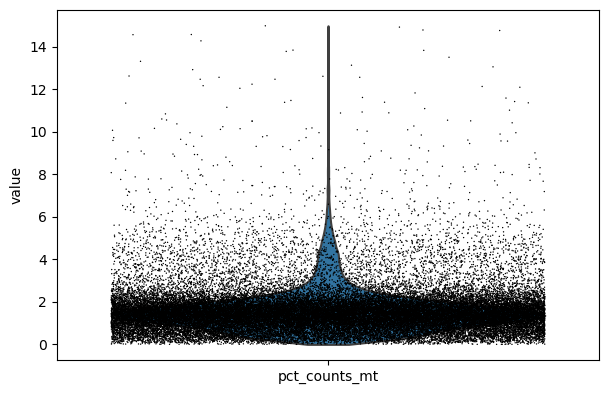

In [22]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [23]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

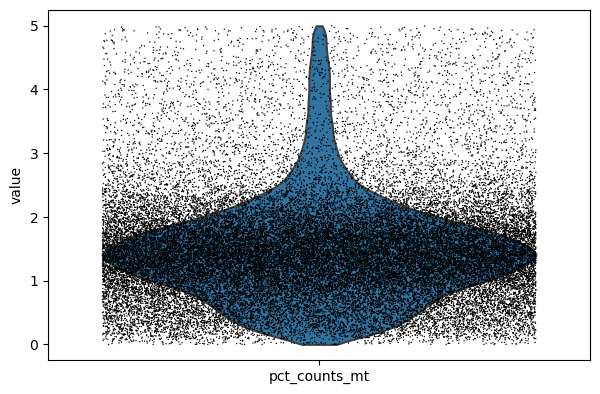

In [24]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [25]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [26]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [27]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [28]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [29]:
df["cell_type"] = adata_filtered.obs["cell_type"].to_numpy()

In [30]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [31]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [32]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [33]:
df

x,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,RP11-54O7.16,...,CTA-243E7.2,CTA-992D9.8,RP11-46E17.6,RP1-302D9.3,PRR34-AS1,AF212831.2,AP000470.2,barcode,cell_type,barcode_cont
0,0.0,0.356834,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTCTGTCTGACTCTGTGTCTGTCTGTGTGT-1-1,II-Motors,0
1,0.0,0.000000,0.384491,0.0,0.000000,0.384491,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTCTGTGTGTGTGAGTCTGTGTCTCTGTGTGT-1-1;CAGTGAGTC...,II-NPvMB,1
2,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGAGACTGTGACTGTGTGTCTCTCTGTCT-1-1,II-NPvMB,2
3,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCTCTGTGTGTGTCTCTCTGTCAGTCTCT-1-1,II-NPMHB,3
4,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGTCTGTGTCTCAGTGTGTCTCACTGTCA-1-1,II-NPMHB,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42635,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT-3-2;CTCTGACAC...,II-NPaHB,33303
42636,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGTGTGACACAGACTGTGTGTGTCAGTGT-3-2,II-NPvMB,33304
42637,0.0,0.000000,0.000000,0.0,0.677093,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTCTGTGTGAGACAGTGTGTCTCTCAGTGACT-3-2;CCCCGTGCG...,II-NPaHB,33305
42638,0.0,0.756515,0.756515,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTGTGTGTGACAGTGTGTCAGTCTGTGTCT-3-2,II-NPpHB,33306


In [34]:
df = df.drop("barcode", axis=1)

In [35]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/you_stage2_barcode_all_genes.pkl')
